

---

## **Problem Statement**

In many real-world scenarios, users seek contextual information about the current date and time as part of their natural language queries. For example:

* *“What is today’s date?”*
* *“Can you tell me the current time before I schedule a meeting?”*

While large language models (LLMs) can generate approximate or static answers, they are **not inherently aware of real-time system information**. As a result, they may provide outdated or fabricated responses when asked about the current date or time.

To ensure accuracy, an intelligent assistant must:

1. **Understand natural language queries referring to temporal context.**
2. **Automatically invoke tools that fetch real-time system date and time.**
3. **Integrate tool outputs into a conversational, human-friendly response.**

This functionality is crucial in **productivity tools, scheduling assistants, personal reminders, and business applications**, where real-time awareness significantly enhances user experience and reliability.

---

## **Objective**

Design and implement a **LangChain-powered agent** that integrates real-time utilities for date and time. The agent should:

* **Detect** when a user query involves current date or time.
* **Automatically call the appropriate tool** (`get_current_date` or `get_current_time`).
* **Leverage LangChain’s tool-calling framework** to handle reasoning and orchestration.
* **Maintain a reasoning trace** using `agent_scratchpad` for clarity.
* **Provide responses** in a conversational and context-aware format, ensuring outputs are both precise and user-friendly.

---



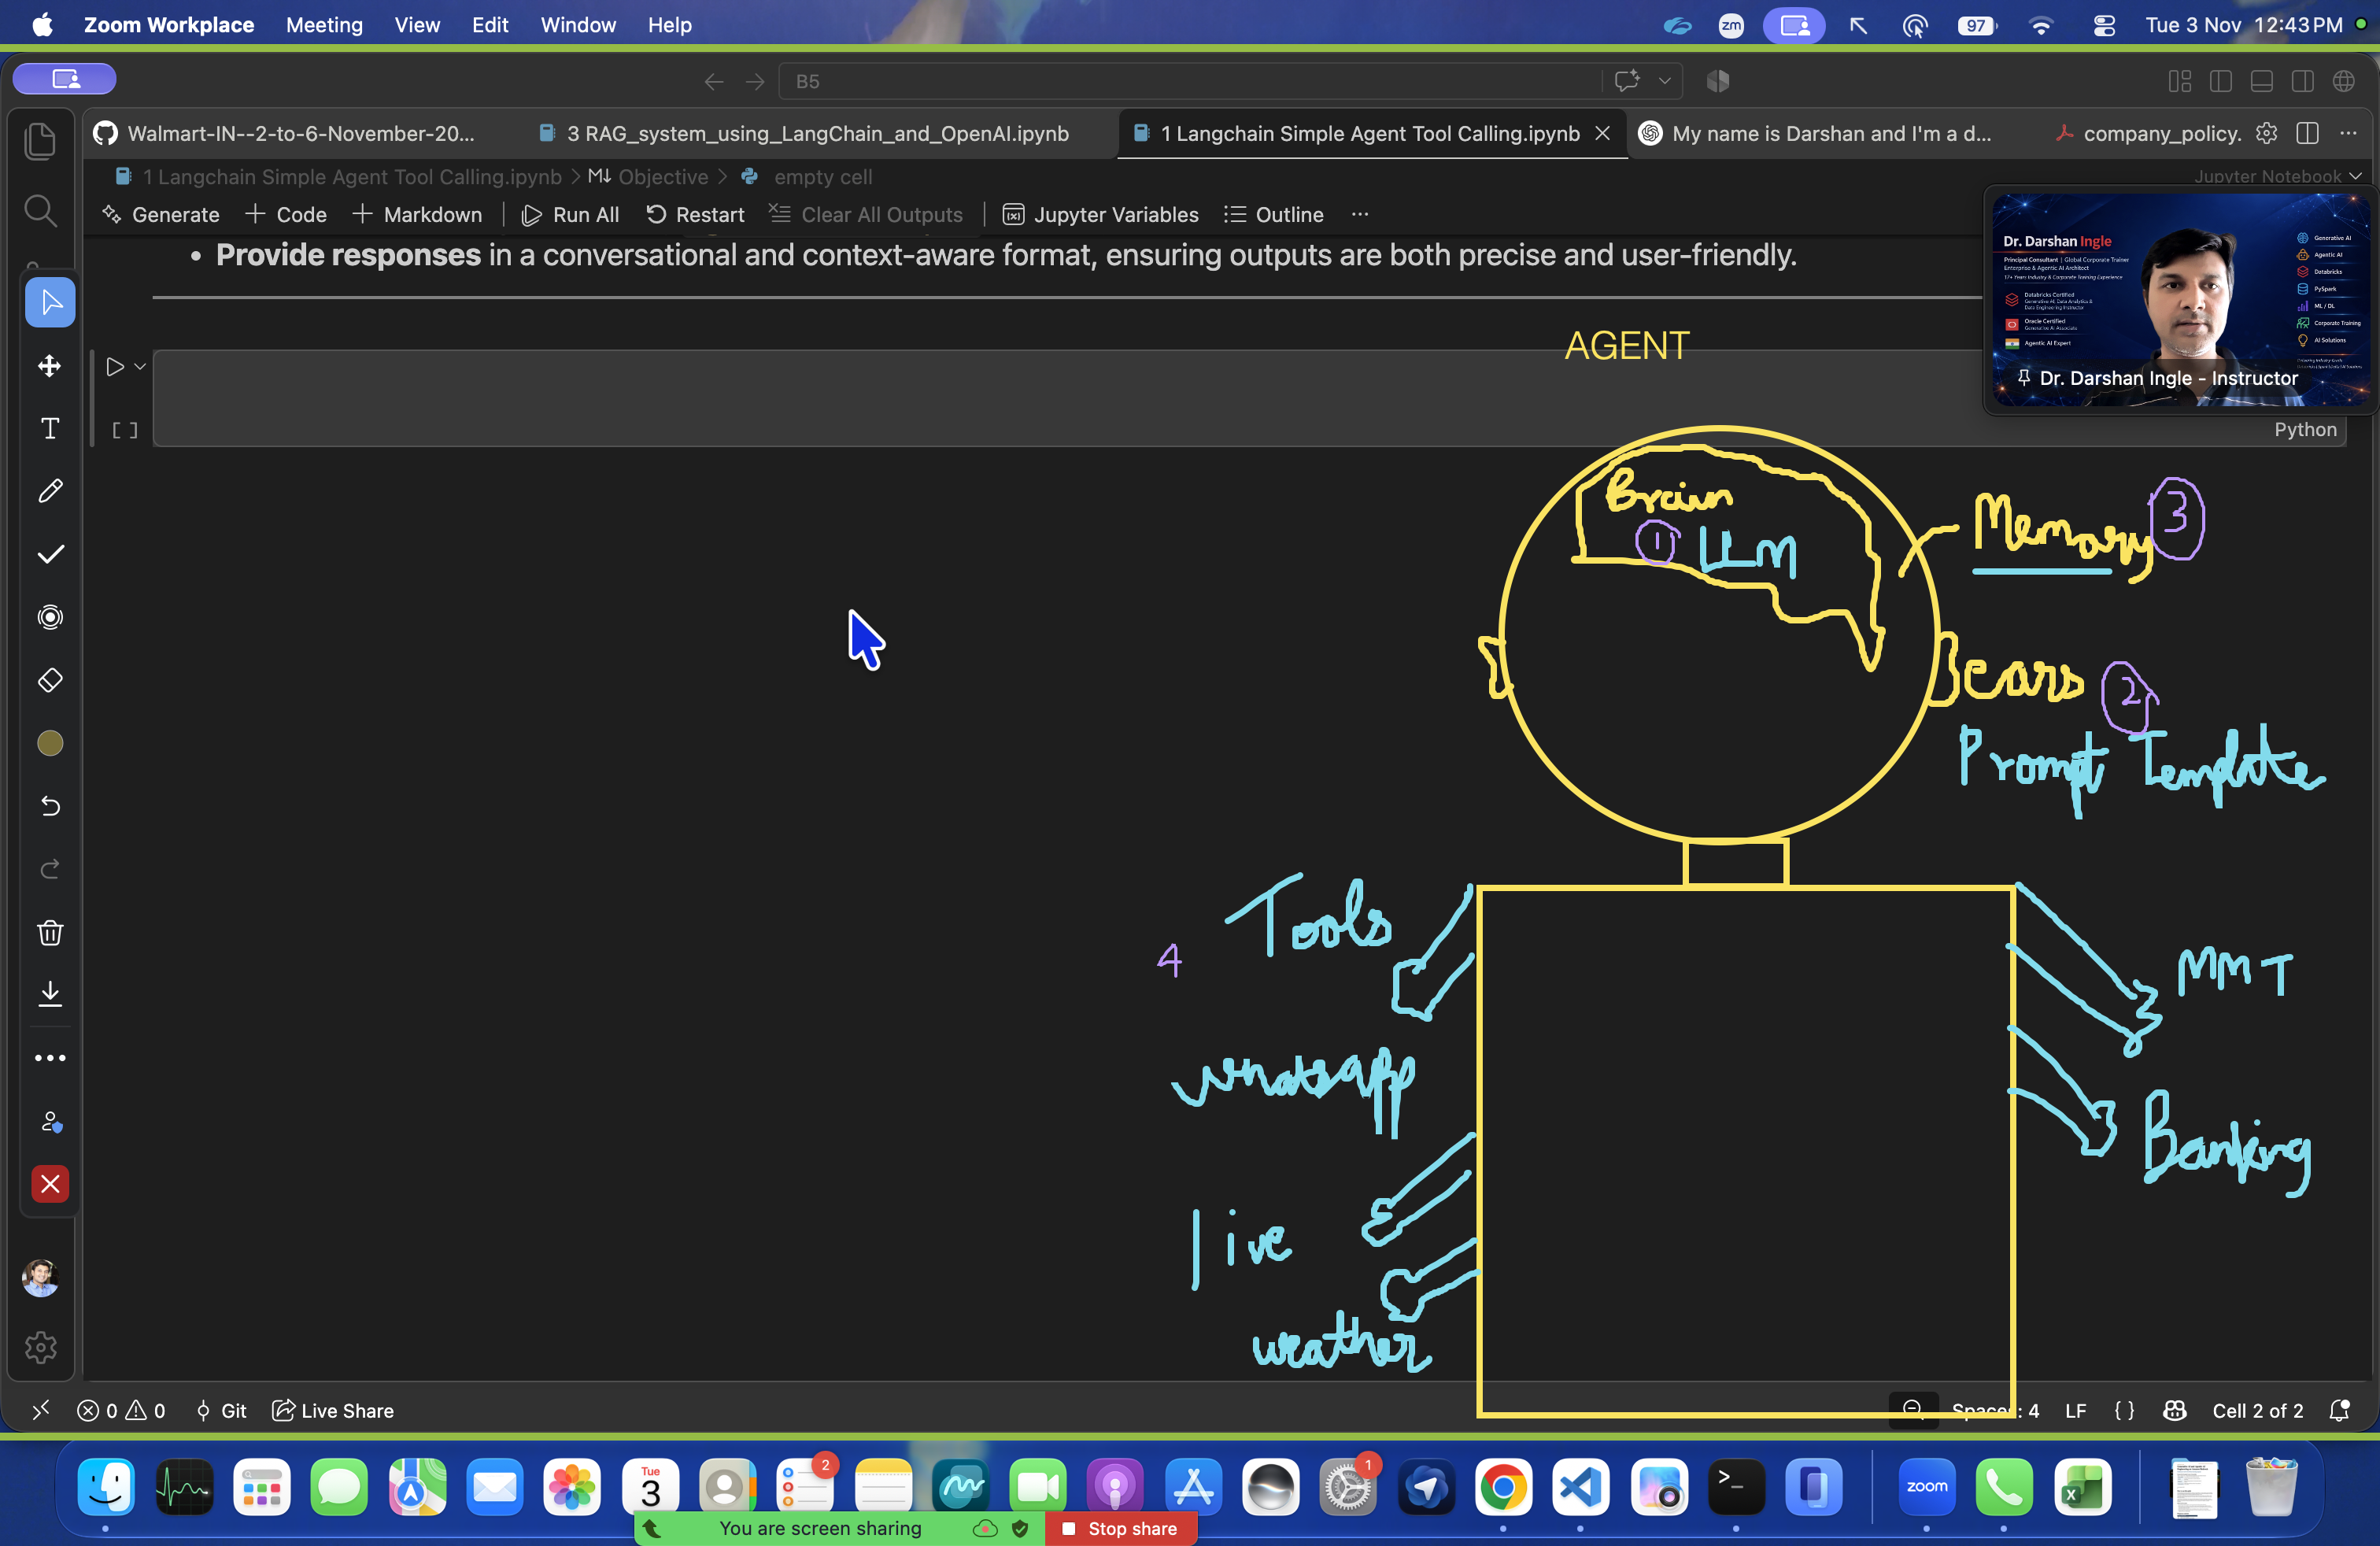

In [1]:
# Agent components:
# 1. Brain: LLM (e.g., GPT-4, Claude 3)
# 2. Prompt Template: Guides the LLM's responses.
# 3. Tools: Functions the agent can call to perform tasks.
# 4. Memory: Stores context from previous interactions.

In [2]:
# Langchain Simple Agent

# Import required libraries

# For calling the Openai API
from langchain_openai import ChatOpenAI # LLM BRAIN - ENGINE

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder # MESSAGES - CHASSIS
# ChatPromptTemplate: It is used to create a prompt template for chat models. This helps in structuring the input for the model.
# MessagesPlaceholder: It is used to indicate where the messages should be placed in the prompt template. This allows for dynamic insertion of messages during the conversation.

from langchain.tools import tool # HANDS - DASHBOARD
# tool: It is used to define a tool that can be called by the agent. This allows the agent to perform specific actions or retrieve information.

from langchain.agents import create_tool_calling_agent, AgentExecutor
# create_tool_calling_agent: It is used to create an agent that can call tools. This allows the agent to use the defined tools to perform tasks.
# AgentExecutor: It is used to execute the agent. This allows the agent to process inputs

In [3]:
# Load the environment variables from the .env file
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [4]:
llm = ChatOpenAI(model="gpt-4o")
# https://python.langchain.com/docs/integrations/chat/openai/

In [5]:
# Step 5: Create prompt template (IMPORTANT: include input & agent_scratchpad)

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a smart assistant. You can use tools whenever necessary to answer user questions."),
    ("user", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad")  # Required
    # MessagesPlaceholder - A special placeholder used by LangChain agents to store: a. Intermediate reasoning steps, b. Tool calls, c. Tool outputs - ReAct Style (Thoughts, Actions, and Observations)
])

In [20]:
# 1) datetime (built-in)
from datetime import datetime
print(datetime.now())                  # local date+time
print(datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

2026-11-03 12:54:56.311898
2026-11-03 12:54:56


In [21]:
# Install pendulum package for timezone handling
# !pip install pendulum -q

import pendulum

now = pendulum.now("Asia/Kolkata")
print("Date:", now.format("YYYY-MM-DD"))
print("Time:", now.format("HH:mm:ss"))

Date: 2026-11-03
Time: 12:55:18


In [33]:
import requests
from datetime import datetime, timezone
import ntplib

# What is ntplib?
# ntplib is a Python library used to interact with Network Time Protocol (NTP) servers. It allows you to retrieve the current time from NTP servers, which is useful for applications that require accurate timekeeping.
# This function fetches the current UTC time from an internet source using ntplib and falls back to Google's server time if ntplib fails.

def get_internet_utc():
    try:
        client = ntplib.NTPClient()
        response = client.request("pool.ntp.org")
        print("Hitting WorldTimeAPI, got data:", response)
        return datetime.fromtimestamp(response.tx_time, timezone.utc)
    except Exception:
        r = requests.head("https://google.com")
        server_time = r.headers["Date"]
        print("Hitting Google, got server time:", server_time)
        return datetime.strptime(server_time, "%a, %d %b %Y %H:%M:%S %Z").replace(tzinfo=timezone.utc)

utc_now = get_internet_utc()
print("Reliable UTC time:", utc_now)


Hitting WorldTimeAPI, got data: <ntplib.NTPStats object at 0x17db20610>
Reliable UTC time: 2026-11-03 07:33:54.970630+00:00


In [23]:
# Tool Definitions
import pendulum

@tool
def get_current_date_in_india():
    """Returns the current date in India."""
    now = pendulum.now("Asia/Kolkata")
    return f"Current date in India: {now.format('YYYY-MM-DD')}"

@tool
def get_current_time_in_india():
    """Returns the current time in India."""
    now = pendulum.now("Asia/Kolkata")
    return f"Current time in India: {now.format('HH:mm:ss')}"

tools = [get_current_date_in_india, get_current_time_in_india]

In [24]:
agent = create_tool_calling_agent(
    llm=llm,
    tools=tools,
    prompt=prompt
)

In [25]:
# Wrap the agent in an AgentExecutor
agent_executor = AgentExecutor(
    agent=agent,
    tools=tools,
    verbose=True # Set verbose=True to see the agent's reasoning and tool calls in the output
)

In [9]:
response = agent_executor.invoke({"input": "Explain the process of photosynthesis in 5 lines."})
print(response['output'])
# print(response)

# How does the Agent work?
# 1. The user provides an input query to the agent.
# 2. The query "input" is passed to the agent's prompt template, which structures the input for the LLM.
# 3. This structured prompt is then sent to the LLM (e.g., GPT-4) for processing. LLM is good at understanding and generating human-like text based on the input it receives.
# 4. The LLM processes the input and looks for any tool calls if available. If the LLM determines that a tool is available, then it will call the tool with the appropriate parameters and get back the output from the tool. However, if the LLM determines that no tool is available, then it will see if it can answer the question itself based on its training data and the context provided in the prompt. If it can answer the question, it will generate a response directly. If it cannot answer the question, it will generate a response indicating that it cannot answer the question.
# 5. If the tool is called, the output from the tool is then passed back to the LLM as part of the agent's scratchpad (intermediate reasoning steps). The LLM can then use this information to generate a final response to the user's query.
# 6. The final response is then returned to the user.

# Ques -> AGENT(llm+tools+prompt) -> Prompt -> llm(brain) -> check for tools -> No tools -> llm(brain) -> Can I answer? -> Yes/No -> If No -> I cannot answer. If Yes -> Generate response -> Return response to user



> Entering new AgentExecutor chain...
Photosynthesis is the process by which green plants, algae, and some bacteria convert light energy into chemical energy, specifically glucose, using sunlight, carbon dioxide, and water. In the chloroplasts, chlorophyll captures sunlight to split water molecules into oxygen, which is released as a byproduct, and hydrogen. The hydrogen combines with carbon dioxide in the Calvin cycle to form glucose. ATP and NADPH generated during the light-dependent reactions power the conversion of carbon dioxide into glucose. This process is essential for the production of oxygen and the sustenance of the food chain.

> Finished chain.
Photosynthesis is the process by which green plants, algae, and some bacteria convert light energy into chemical energy, specifically glucose, using sunlight, carbon dioxide, and water. In the chloroplasts, chlorophyll captures sunlight to split water molecules into oxygen, which is released as a byproduct, and hydrogen. The hydro

In [10]:
response = agent_executor.invoke({"input": "Explain the process of photosynthesis in 5 bullet points."})
print(response['output'])




> Entering new AgentExecutor chain...
- **Light Absorption**: Plants absorb sunlight using chlorophyll, a green pigment in the chloroplasts. This light energy is essential for driving the chemical reactions in photosynthesis.

- **Water Splitting**: The absorbed light energy splits water molecules (H2O) into oxygen, protons, and electrons. Oxygen is released as a byproduct into the atmosphere.

- **Carbon Dioxide Fixation**: Carbon dioxide (CO2) from the atmosphere enters the plant leaves through stomata. It is then fixed into organic molecules in the Calvin cycle.

- **Sugar Formation**: Using the energy from ATP and NADPH (produced in the light-dependent reactions), carbon dioxide is converted into simple sugars like glucose, which serves as an energy source for the plant.

- **Energy Storage**: The glucose produced can be used immediately for energy or converted into other carbohydrates such as starch for storage, which can be utilized later as an energy source.

> Finished chain.

In [11]:
response = agent_executor.invoke({"input": "What is the capital of India?"})
print(response['output'])




> Entering new AgentExecutor chain...
The capital of India is New Delhi.

> Finished chain.
The capital of India is New Delhi.


In [12]:
response = agent_executor.invoke({"input": "What is the capital of New Delhi?"})
print(response['output'])




> Entering new AgentExecutor chain...
New Delhi is itself the capital of India.

> Finished chain.
New Delhi is itself the capital of India.


In [13]:
response = agent_executor.invoke({"input": "My name is Darshan and I want to become a data scientist. Please guide me with three successful career tips."})
print(response['output'])




> Entering new AgentExecutor chain...
Certainly, Darshan! Here are three successful career tips for aspiring data scientists:

1. **Solidify Your Foundation in Mathematics and Statistics**: 
   - Data science is heavily reliant on mathematics, especially statistics and linear algebra. Make sure you understand key concepts such as probability distributions, hypothesis testing, and regression analysis. Strengthen your understanding of mathematical concepts like matrices, vectors, and calculus, as they form the backbone of machine learning algorithms.

2. **Gain Proficiency in Programming and Tools**:
   - Learn programming languages that are essential for data science, such as Python and R. These languages are widely used for data manipulation, analysis, and visualization. Familiarize yourself with libraries and tools like Pandas, NumPy, TensorFlow, and scikit-learn. Also, enhance your skills in data visualization tools like Matplotlib, Seaborn, or Tableau to effectively communicate yo

In [14]:
response = agent_executor.invoke({"input": "Do do you recollect my name?"})
print(response['output'])




> Entering new AgentExecutor chain...
I don't have access to personal data about users unless it has been shared with me in the course of our conversation. Could you remind me of your name?

> Finished chain.
I don't have access to personal data about users unless it has been shared with me in the course of our conversation. Could you remind me of your name?


In [26]:
response = agent_executor.invoke({"input": "What is today's date in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


Current date in India: 2026-11-03Today's date in India is November 3, 2026.

> Finished chain.
Today's date in India is November 3, 2026.


In [27]:
response = agent_executor.invoke({"input": "What is today's date in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


Current date in India: 2026-11-03Today's date in India is November 3, 2026.

> Finished chain.
Today's date in India is November 3, 2026.


In [28]:
response = agent_executor.invoke({"input": "What is today's date in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


Current date in India: 2026-11-03Today's date in India is November 3, 2026.

> Finished chain.
Today's date in India is November 3, 2026.


In [29]:
response = agent_executor.invoke({"input": "What is current time in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_time_in_india` with `{}`


Current time in India: 13:00:27The current time in India is 13:00:27.

> Finished chain.
The current time in India is 13:00:27.


In [30]:
response = agent_executor.invoke({"input": "What is todays date and current time in Pakistan?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


Current date in India: 2026-11-03
Invoking: `get_current_time_in_india` with `{}`


Current time in India: 13:00:55Today's date in India is 3rd November 2026, and the current time is 1:00 PM.

Since India is 30 minutes ahead of Pakistan, the date in Pakistan is also the 3rd of November 2026, but the time is 12:30 PM.

> Finished chain.
Today's date in India is 3rd November 2026, and the current time is 1:00 PM.

Since India is 30 minutes ahead of Pakistan, the date in Pakistan is also the 3rd of November 2026, but the time is 12:30 PM.


# Happy Learning